# Chapter 6: Characteristic Functions and the Central Limit Theorem

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch06/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibrahimguney/statistical-theory/blob/main/notebooks/ch_06.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Convergence to the CLT: Skewness and Kurtosis

For $X_i\iid\text{Exp}(\lambda=0.5)$, $\mu=\sigma=2$. A cumulant calculation shows that the skewness of $Z_n$ is $2/\sqrt n$ and its excess kurtosis $6/n$; the simulated values are compared with these theoretical values.

*Source file:* `code/ch06/c06_1_clt_skewness_kurtosis.py`

In [2]:
import numpy as np
import scipy.stats as stats

rng = np.random.default_rng(42)
lam = 0.5
for n in [1, 5, 30, 200]:
    samples = rng.exponential(scale=1.0/lam, size=(100_000, n))
    z = (np.mean(samples, axis=1) - 2.0) / (2.0 / np.sqrt(n))
    print(f"n = {n:3d} | Skewness: {stats.skew(z):6.3f} (theory {2/np.sqrt(n):5.3f}) | Kurtosis: {stats.kurtosis(z):6.3f} (theory {6/n:5.3f})")

n =   1 | Skewness:  2.023 (theory 2.000) | Kurtosis:  6.238 (theory 6.000)
n =   5 | Skewness:  0.903 (theory 0.894) | Kurtosis:  1.281 (theory 1.200)
n =  30 | Skewness:  0.356 (theory 0.365) | Kurtosis:  0.204 (theory 0.200)


n = 200 | Skewness:  0.148 (theory 0.141) | Kurtosis:  0.040 (theory 0.030)


## Checking the Berry–Esseen Bound by Exact Computation

Since a sum of Exp(1) variables is $\text{Gamma}(n,1)$, the CDF of $Z_n$ can be computed exactly, without simulation: $\P(Z_n\le x)=G_n(n+x\sqrt n)$.

*Source file:* `code/ch06/c06_2_berry_esseen_exact.py`

In [3]:
import numpy as np
from scipy import stats, integrate

rho = integrate.quad(lambda x: abs(x - 1)**3 * np.exp(-x), 0, np.inf)[0]   # E|X-1|^3
x = np.linspace(-6, 6, 20_001)
print(f"rho = E|X-mu|^3 = {rho:.4f}")
for n in [1, 10, 100, 1000]:
    Fn = stats.gamma.cdf(n + x*np.sqrt(n), a=n)
    sup = np.max(np.abs(Fn - stats.norm.cdf(x)))
    print(f"n={n:5d} | sup|F_n - Phi| = {sup:.5f} | Berry-Esseen bound = {0.4748*rho/np.sqrt(n):.5f} | sqrt(n)*sup = {np.sqrt(n)*sup:.4f}")

rho = E|X-mu|^3 = 2.4146
n=    1 | sup|F_n - Phi| = 0.15861 | Berry-Esseen bound = 1.14643 | sqrt(n)*sup = 0.1586
n=   10 | sup|F_n - Phi| = 0.04211 | Berry-Esseen bound = 0.36253 | sqrt(n)*sup = 0.1332
n=  100 | sup|F_n - Phi| = 0.01330 | Berry-Esseen bound = 0.11464 | sqrt(n)*sup = 0.1330
n= 1000 | sup|F_n - Phi| = 0.00421 | Berry-Esseen bound = 0.03625 | sqrt(n)*sup = 0.1330


## Visualising the CLT and the Continuity Correction

*Source file:* `code/ch06/c06_3_clt_visualisation_continuity_correction.py`

Exact P(X<=25)                    = 0.1631
Normal approx. (no correction)    = 0.1376
Normal approx. (with correction)  = 0.1631


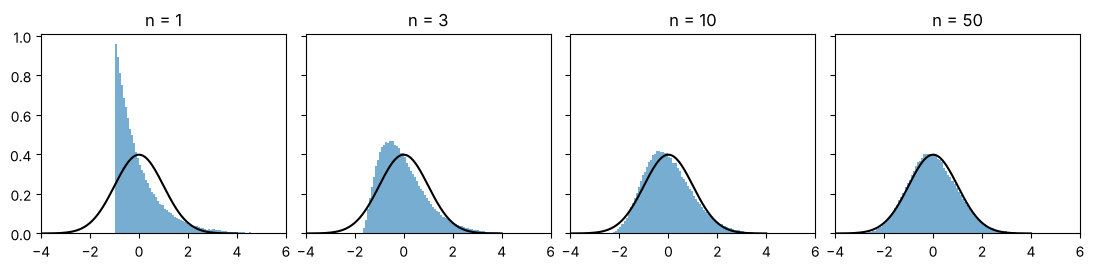

In [4]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
zz = np.linspace(-4, 4, 300)
for ax, n in zip(axes, [1, 3, 10, 50]):
    z = (rng.exponential(size=(200_000, n)).mean(axis=1) - 1) * np.sqrt(n)
    ax.hist(z, bins=120, range=(-4, 6), density=True, color="tab:blue", alpha=0.6)
    ax.plot(zz, stats.norm.pdf(zz), "k-", lw=1.5)
    ax.set_title(f"n = {n}"); ax.set_xlim(-4, 6)
fig.tight_layout(); fig.savefig("clt_ustel.pdf")

n, p, k = 100, 0.3, 25
mu, sd = n*p, np.sqrt(n*p*(1-p))
print(f"Exact P(X<=25)                    = {stats.binom.cdf(k, n, p):.4f}")
print(f"Normal approx. (no correction)    = {stats.norm.cdf((k - mu)/sd):.4f}")
print(f"Normal approx. (with correction)  = {stats.norm.cdf((k + 0.5 - mu)/sd):.4f}")